<a href="https://colab.research.google.com/github/piaseckazaneta/Python/blob/main/Rodzice_w_Branzy_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Rodzice w branży Data: Mit pasywnego pracownika a twarde realia danych

### Kontekst i problem badawczy
Dynamiczny rozwój technologii, kultura ciągłego dokształcania i presja na elastyczność stawiają przed specjalistami Data wysokie wymagania. Wokół pracujących rodziców narosło wiele stereotypów: od przekonania o spadku zaangażowania i "odpuszczaniu" rozwoju, po oczekiwanie taryfy ulgowej.

Niniejsza analiza weryfikuje te założenia w oparciu o twarde dane, porównując realia pracy rodziców z sytuacją osób bezdzietnych.

### Cel projektu
Zbadanie wpływu ról opiekuńczych na codzienną praktykę zawodową w branży Data oraz zidentyfikowanie ryzyk operacyjnych i przewag, jakie pracujący rodzice wnoszą do organizacji.

### Pytania badawcze (4 filary analizy)
1. **Higiena czasu pracy:** Czy rodzicielstwo oznacza nadgodziny, czy wymusza dyscyplinę sztywnego etatu?
2. **Model pracy (Paradoks elastyczności):** Kto w branży Data doświadcza największego rozdźwięku między preferowanym a obecnym trybem pracy?
3. **Dojrzałość projektowa:** Czy zespoły Data posiadają procedury backupu na wypadek nagłych nieobecności i kto bierze na siebie ciężar pożarów ad-hoc?
4. **Potencjał rozwojowy:** Czy deficyt czasu u rodziców hamuje ich rozwój merytoryczny i głód wiedzy?

### Próba badawcza i metodologia
* **Źródło danych:** Wielka Ankieta Branży Data
* **Wielkość próby:** $N = 297$ specjalistów
* **Podział ankietowanych na 4 grupy:** 4 rozłączne profile: *Matka* ($N=45$), *Ojciec* ($N=38$), *Kobieta bez dzieci* ($N=122$), *Mężczyzna bez dzieci* ($N=92$)

## 1. Środowisko i wstępna obróbka danych

### 1.1. Import bibliotek i globalna konfiguracja stylów

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
pd.set_option('display.max_columns', None)

In [ ]:
def rysuj_wykres_filaru(seria_danych, tytul, podtytul, jednostka='%'):
    if isinstance(seria_danych, pd.DataFrame):
        seria_danych = seria_danych.iloc[:, 0]

    fig, ax = plt.subplots(figsize=(9, 4), dpi=150)

    dane = seria_danych.sort_values(ascending=True)
    kolory = [kolory_profili.get(k, '#4a90e2') for k in dane.index]

    bars = ax.barh(dane.index, dane.values, color=kolory, height=0.55)

    max_val = dane.values.max() if len(dane) > 0 else 100
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + (max_val * 0.02),
            bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}{jednostka}",
            va='center',
            ha='left',
            fontsize=10,
            fontweight='bold',
            color='#333333'
        )

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_color('#cccccc')

    ax.xaxis.set_visible(False)
    ax.tick_params(axis='y', labelsize=10)

    # --- POPRAWKA TYTUŁU I PODTYTUŁU ---
    # Tytuł główny (bold, większy)
    ax.text(
        0.0, 1.18,
        tytul,
        transform=ax.transAxes,
        fontsize=12,
        fontweight='bold',
        color='#1a1a1a',
        ha='left'
    )
    # Podtytuł (mniejszy, szary, z bezpiecznym odstępem poniżej tytułu)
    ax.text(
        0.0, 1.08,
        podtytul,
        transform=ax.transAxes,
        fontsize=9,
        color='#666666',
        ha='left'
    )

    plt.tight_layout()
    plt.show()

### 1.2. Wczytanie i łączenie modułów ankiety

In [ ]:
ogolne = pd.read_csv("0.df_ogolne.csv")
projekty = pd.read_csv("3.df_projekty.csv")
org_pracy = pd.read_csv("4.df_organizacja_pracy.csv")
well_being = pd.read_csv("5.df_well_being.csv")
przyszlosc = pd.read_csv("6.df_przyszlosc.csv")

tables = [ogolne, projekty, org_pracy, well_being, przyszlosc]

In [ ]:
# 1. Połączenie tabel (zakładam zgodność indeksów 297 wierszy)
df_rodzice = pd.concat([
    ogolne,
    projekty,
    well_being,
    przyszlosc,
    org_pracy], axis=1)

df_rodzice = df_rodzice.loc[:, ~df_rodzice.columns.duplicated()]

### 1.3. Selekcja zmiennych i standaryzacja nazewnictwa

In [ ]:
# Słownik mapujący: 'stara_długa_nazwa': 'nowa_zwięzła_nazwa'
mapowanie_kolumn = {
    # --- Metryki podstawowe (Demografia i stanowisko) ---
    'poziom stanowiska (seniority)': 'seniority',
    'lata doświadczenia': 'doswiadczenie_lata',
    'ile lat pracujesz na tym stanowisku': 'staz_na_stanowisku',
    'wielkość firmy, w której pracujesz': 'wielkosc_firmy',
    'w jakiej formie jesteś obecnie zatrudniony/a': 'forma_zatrudnienia',
    # --- Filar 1: Higiena i ramy czasu pracy ---
    'ile godzin dziennie średnio pracujesz': 'godziny_dziennie',
    'jak często zdarza ci się pracować po godzinach lub w weekendy': 'nadgodziny',
    'jak oceniasz swoją równowagę między pracą a życiem prywatnym (work-life balance)': 'wlb',
    'jak oceniasz tempo pracy na swoim stanowisku': 'tempo_pracy',
    # --- Filar 2: Model pracy (obecny vs oczekiwany) ---
    'w jakim modelu pracujesz na co dzień': 'model_obecny',
    'jak chciał(a)byś pracować na co dzień': 'model_wymarzony',
    # --- Filar 3: Dojrzałość projektowa i bezpieczeństwo ---
    'czy masz w swoich projektach "backup", czyli osoby, które są zaznajomione z twoimi projektami i mogłyby cię zastąpić w razie nieobecności': 'backup',
    'jak często realizujesz zadania ad hoc (jednorazowe, nieplanowane zapytania, np. szybkie analizy na potrzeby biznesu)': 'zadania_adhoc',
    'nad iloma projektami obecnie pracujesz': 'liczba_projektow',
    'jak oceniasz swoją samodzielność w kwestiach technicznych (np. wybór narzędzi, metod, rozwiązywanie problemów technicznych)': 'samodzielnosc_tech',
    'jak oceniasz swoją samodzielność w kwestiach biznesowych (np. definiowanie problemu, ustalanie zakresu analizy, interpretacja wyników)': 'samodzielnosc_biz',
    # --- Filar 4: Rozwój, zmiana pracy i satysfakcja ---
    'w jaki stopniu jesteś zadowolona/y ze swojej pracy': 'satysfakcja',
    'czy obecnie szkolisz się lub rozwijasz swoje umiejętności zawodowe': 'doksztalcanie',
    'czy czujesz, że rozwijasz się zawodowo na swoim obecnym stanowisku': 'rozwoj_w_pracy',
    'czy obecnie rozważasz zmianę pracy': 'mysli_o_zmianie_pracy',
    'jak oceniasz obecny rynek pracy w branży data / it': 'ocena_rynku',
    'jak oceniasz przyszłość branży data / it': 'przyszlosc_branzy',
    # --- Dodatkowe czynniki obciążenia i benefity ---
    'czy oprócz głównej pracy wykonujesz dodatkowe zlecenia lub projekty (czyli „dorabiasz”)': 'dorabianie',
    'benefity | elastyczne godziny pracy': 'benefit_elastyczne_godziny',
    'benefity | możliwość pracy z dowolnego miejsca': 'benefit_praca_z_dowolnego_miejsca',
    'benefity | budżet na home office / sprzęt do pracy zdalnej': 'benefit_home_office',
    'benefity | dni wolne od spotkań': 'benefit_dni_bez_spotkan',
    'benefity | dofinansowanie nauki / szkoleń / kursów': 'benefit_dofinansowanie_nauki',
}

# Zmiana nazw w głównej tabeli df
df_rodzice = df_rodzice.rename(columns=mapowanie_kolumn)

### 1.4. Definicja profili badawczych (`profil_grupy`)

In [ ]:
# 2. Definicja profilu (Płeć x Rodzicielstwo)
conditions = [
    (df_rodzice['płeć'].str.lower().str.contains('kobieta', na=False)) & (df_rodzice['rodzic'] == True),
    (df_rodzice['płeć'].str.lower().str.contains('kobieta', na=False)) & (df_rodzice['rodzic'] == False),
    (df_rodzice['płeć'].str.lower().str.contains('mężczyzn|mezczyzn', na=False)) & (df_rodzice['rodzic'] == True),
    (df_rodzice['płeć'].str.lower().str.contains('mężczyzn|mezczyzn', na=False)) & (df_rodzice['rodzic'] == False)
]
choices = ['Matka', 'Kobieta bez dzieci', 'Ojciec', 'Mężczyzna bez dzieci']

df_rodzice['profil_grupy'] = np.select(conditions, choices, default='Inne/Brak danych')

# Sprawdzenie liczebności grup
print(df_rodzice['profil_grupy'].value_counts())

profil_grupy
Kobieta bez dzieci      122
Mężczyzna bez dzieci     91
Matka                    45
Ojciec                   39
Name: count, dtype: int64


## 2. Analiza empiryczna (4 Filary)

### 2.1. Filar 1: Higiena czasu pracy – dyscyplina etatu a kultura nadgodzin

Weryfikacja hipotezy: „Czy rodzicielstwo wymusza sztywne trzymanie się 8 godzin pracy kosztem pracy w weekendy, czy może to osoby bez dzieci częściej biorą nadgodziny?”

In [ ]:
df_rodzice['godziny_dziennie'].unique()

array(['8 godzin', '9–10 godzin', 'mniej niż 6 godzin', '6–7 godzin', nan,
       'więcej'], dtype=object)

In [ ]:
godziny_summary = (
    pd.crosstab(
        df_rodzice['profil_grupy'],
        df_rodzice['godziny_dziennie'],
        normalize='index'
    ) * 100
).round(1)

print('DZIENNY CZAS PRACY (%)')
print(godziny_summary)

DZIENNY CZAS PRACY (%)
godziny_dziennie      6–7 godzin  8 godzin  9–10 godzin  mniej niż 6 godzin  \
profil_grupy                                                                  
Kobieta bez dzieci          20.8      56.7         11.7                 9.2   
Matka                       17.8      71.1          6.7                 4.4   
Mężczyzna bez dzieci        14.4      58.9         11.1                10.0   
Ojciec                      13.2      68.4         10.5                 7.9   

godziny_dziennie      więcej  
profil_grupy                  
Kobieta bez dzieci       1.7  
Matka                    0.0  
Mężczyzna bez dzieci     5.6  
Ojciec                   0.0  


In [ ]:
nadgodziny_summary = (
    pd.crosstab(
        df_rodzice['profil_grupy'],
        df_rodzice['nadgodziny'],
        normalize='index'
    ) * 100
).round(1)

print('NADGODZINY (%)')
print(nadgodziny_summary)

NADGODZINY (%)
nadgodziny            czasami (kilka razy w miesiącu)  nigdy  \
profil_grupy                                                   
Kobieta bez dzieci                               28.9   27.3   
Matka                                            22.2   31.1   
Mężczyzna bez dzieci                             22.2   22.2   
Ojciec                                           13.2   23.7   

nadgodziny            regularnie (w każdym tygodniu)  \
profil_grupy                                           
Kobieta bez dzieci                               8.3   
Matka                                            2.2   
Mężczyzna bez dzieci                            13.3   
Ojciec                                           5.3   

nadgodziny            sporadycznie (raz na kilka miesięcy)  
profil_grupy                                                
Kobieta bez dzieci                                    35.5  
Matka                                                 44.4  
Mężczyzna bez dziec

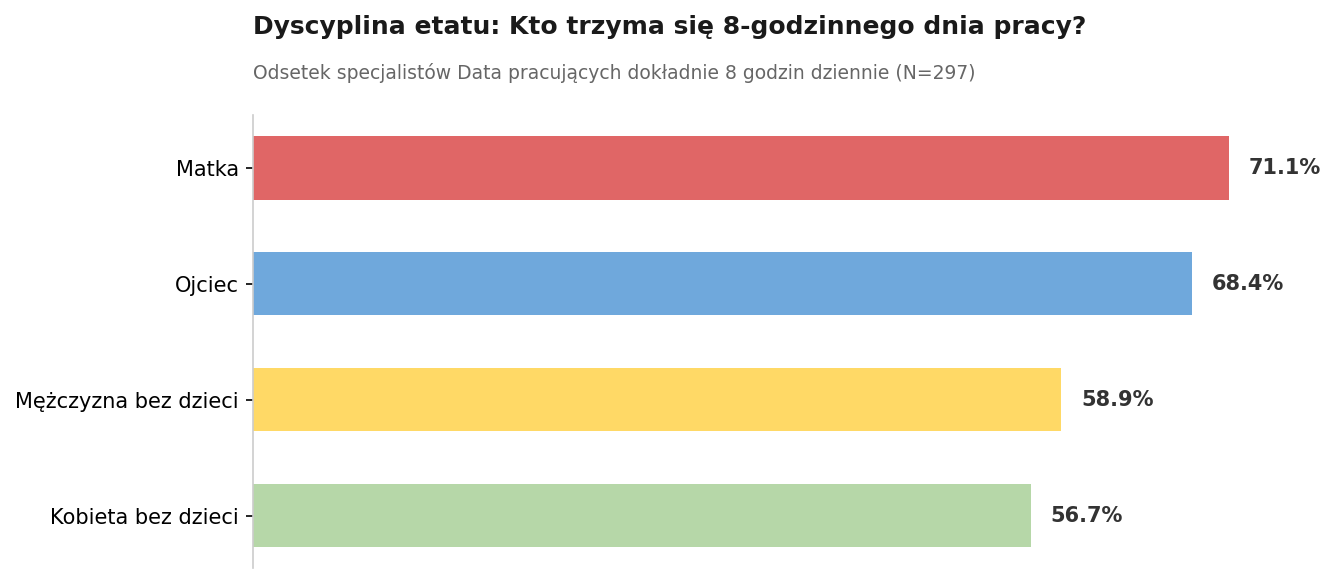

In [ ]:
# Filar 1: Odsetek osób deklarujących dokładnie 8h pracy dziennie
sztywne_8h = godziny_summary['8 godzin']

rysuj_wykres_filaru(
    sztywne_8h,
    tytul="Dyscyplina etatu: Kto trzyma się 8-godzinnego dnia pracy?",
    podtytul="Odsetek specjalistów Data pracujących dokładnie 8 godzin dziennie (N=297)"
)

**WNIOSKI (1 filar)**

Z danych wynika, że elastyczność w IT nie oznacza pełnej dowolności godzin dla każdego. Rodzicielstwo wymusza dyscyplinę.

Blisko 70% rodziców (71.1% matek i 68.4% ojców) pracuje dokładnie 8 godzin dziennie. Wśród osób bezdzietnych wskaźnik ten spada poniżej 60%.

W kategorii pracy powyżej 10 godzin dziennie rodzice notują równe 0.0%. Nie wynika to z braku ambicji, lecz z fizycznych ograniczeń doby i logistyki opiekuńczej (zamykanie placówek, opieka).

Kto gasi pożary w weekendy? Regularne, cotygodniowe nadgodziny to domena osób bez dzieci (13.3% mężczyzn i 8.3% kobiet bez dzieci). U matek regularne nadgodziny to zaledwie 2.2%.

Wniosek biznesowy: Rodzice w zespołach Data to pracownicy o przewidywalnym, stabilnym rytmie dobowym. Nie stanowią zasobu na „nocne sprinty wdrożeniowe”, ale minimalizują ryzyko chaosu i rotacji wynikającej z nieregularnego trybu życia.

### 2.2. Filar 2: Model pracy – oczekiwania a rzeczywistość

Zbadanie luki pomiędzy obecnym modelem pracy a preferencjami pracowników. W której grupie pracownikó występują największe różnice?

In [ ]:
df_rodzice['niedopasowanie_modelu'] = (
    df_rodzice['model_obecny'] != df_rodzice['model_wymarzony']
)

niedopasowanie_grupy = (
    df_rodzice.groupby('profil_grupy')['niedopasowanie_modelu']
    .agg(odsetek_niedopasowania=lambda x: (x.mean() * 100).round(1), liczba_osob='count')
    .sort_values(by='odsetek_niedopasowania', ascending=False)
)
print(niedopasowanie_grupy)

                      odsetek_niedopasowania  liczba_osob
profil_grupy                                             
Kobieta bez dzieci                      45.1          122
Mężczyzna bez dzieci                    41.8           91
Matka                                   33.3           45
Ojciec                                  33.3           39


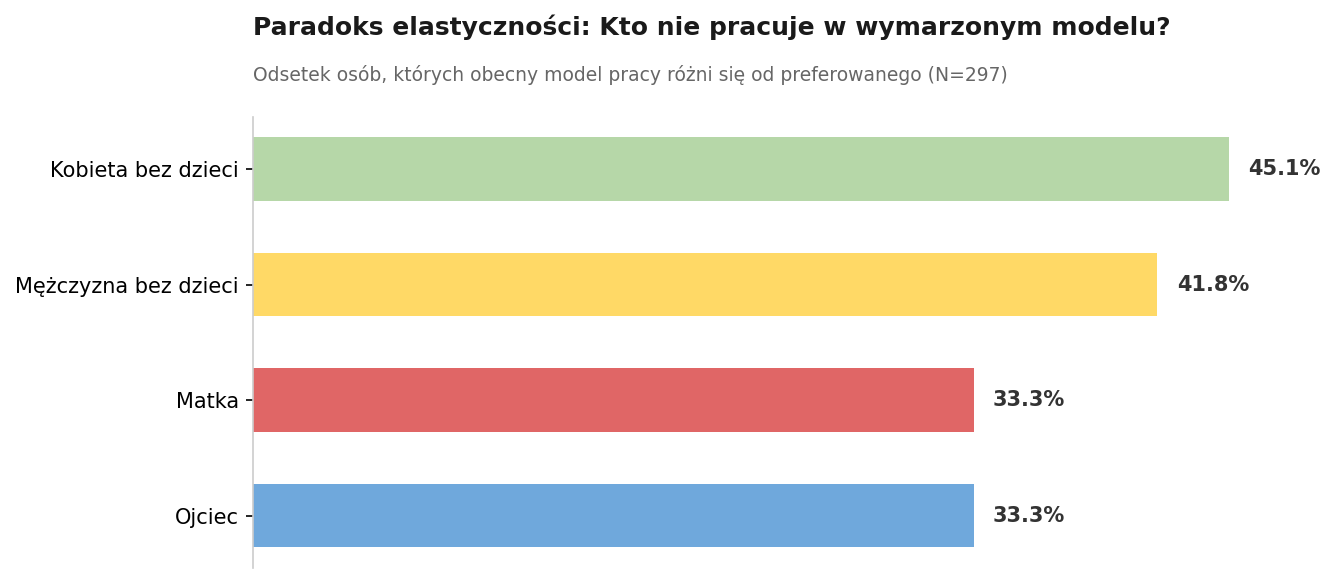

In [ ]:
rysuj_wykres_filaru(
    niedopasowanie_grupy,
    tytul="Paradoks elastyczności: Kto nie pracuje w wymarzonym modelu?",
    podtytul="Odsetek osób, których obecny model pracy różni się od preferowanego (N=297)"
)

**WNIOSKI (2 filar)**

Intuicja podpowiada, że to obciążeni logistyką domową rodzice będą najbardziej sfrustrowani brakiem elastyczności ze strony pracodawców. Dane z ankiety ujawniają jednak zaskakujący paradoks.

Rodzice rzadziej deklarują niedopasowanie: Wśród matek i ojców odsetek osób pracujących niezgodnie ze swoimi preferencjami wynosi dokładnie 33.3% (1 na 3 osoby).

Największy rozjazd dotyka osób bez dzieci: Niedopasowanie sięga 45.1% u kobiet bez dzieci i 41.8% u mężczyzn bez dzieci (niemal co druga osoba).

Dla rodzica model pracy (praca w 100% zdalna lub hybryda z przewagą domu) stanowi warunek przy podejmowaniu zatrudnienia. Rodzice po prostu nie przyjmują ofert, które nie dają im stabilności logistycznej.

Koszty kompromisu u bezdzietnych: Osoby bez dzieci częściej godzą się na oferty hybrydowe ze sztywną obecnością w biurze lub – odwrotnie – tkwią na pełnym home office, doświadczając izolacji i deklarując chęć częstszego kontaktu z zespołem.

Wniosek biznesowy: Sztywna polityka powrotu do biur (Return-to-Office) uderza w obie grupy: u rodziców rodzi ryzyko natychmiastowego odejścia z pracy, z kolei u osób bezdzietnych pogłębia ciche niezadowolenie i spadek zaangażowania.

### 2.3. Filar 3: Dojrzałość projektowa – pożary ad-hoc i brak zastępstwa

Sprawdzenie stopnia ryzyka operacyjnego: czy zespoły zapewniają backup w projektach na wypadek nagłej nieobecności (np. zwolnienia lekarskiego na dziecko) i jak często pracownicy są wybijani z rytmu zadaniami doraźnymi?

In [ ]:
print("Warianty odpowiedzi - backup:")
print(df_rodzice['backup'].value_counts(dropna=False))

print("\nWarianty odpowiedzi - zadania ad-hoc:")
print(df_rodzice['zadania_adhoc'].value_counts(dropna=False))

Warianty odpowiedzi - backup:
backup
częściowo – ktoś ma ogólną wiedzę, ale nie zna szczegółów                         151
tak – jedna lub więcej osób zna szczegóły moich projektów i może mnie zastąpić     64
nie – tylko ja znam szczegóły moich projektów                                      56
trudno powiedzieć / zależy od projektu                                             25
NaN                                                                                 1
Name: count, dtype: int64

Warianty odpowiedzi - zadania ad-hoc:
zadania_adhoc
często – regularnie dostaję takie zapytania    158
sporadycznie                                    82
bardzo często, to większość mojej pracy         35
rzadko lub w ogóle                              22
Name: count, dtype: int64


In [ ]:
tabela_backup = (
    pd.crosstab(
        df_rodzice['profil_grupy'],
        df_rodzice['backup'],
        normalize='index'
    ) * 100
).round(1)

print("BACKUP W PROJEKTACH (%)")
print(tabela_backup)


BACKUP W PROJEKTACH (%)
backup                częściowo – ktoś ma ogólną wiedzę, ale nie zna szczegółów  \
profil_grupy                                                                      
Kobieta bez dzieci                                                 49.2           
Matka                                                              53.3           
Mężczyzna bez dzieci                                               53.8           
Ojciec                                                             47.4           

backup                nie – tylko ja znam szczegóły moich projektów  \
profil_grupy                                                          
Kobieta bez dzieci                                             16.4   
Matka                                                          11.1   
Mężczyzna bez dzieci                                           22.0   
Ojciec                                                         28.9   

backup                tak – jedna lub więcej osób 

In [ ]:
tabela_adhoc = (
    pd.crosstab(
        df_rodzice['profil_grupy'],
        df_rodzice['zadania_adhoc'],
        normalize='index'
    ) * 100
).round(1)

print("ZADANIA AD-HOC (%)")
print(tabela_adhoc)

ZADANIA AD-HOC (%)
zadania_adhoc         bardzo często, to większość mojej pracy  \
profil_grupy                                                    
Kobieta bez dzieci                                        7.4   
Matka                                                    15.6   
Mężczyzna bez dzieci                                      9.9   
Ojciec                                                   25.6   

zadania_adhoc         często – regularnie dostaję takie zapytania  \
profil_grupy                                                        
Kobieta bez dzieci                                           50.8   
Matka                                                        48.9   
Mężczyzna bez dzieci                                         62.6   
Ojciec                                                       43.6   

zadania_adhoc         rzadko lub w ogóle  sporadycznie  
profil_grupy                                            
Kobieta bez dzieci                   9.8          32.0  
Matk

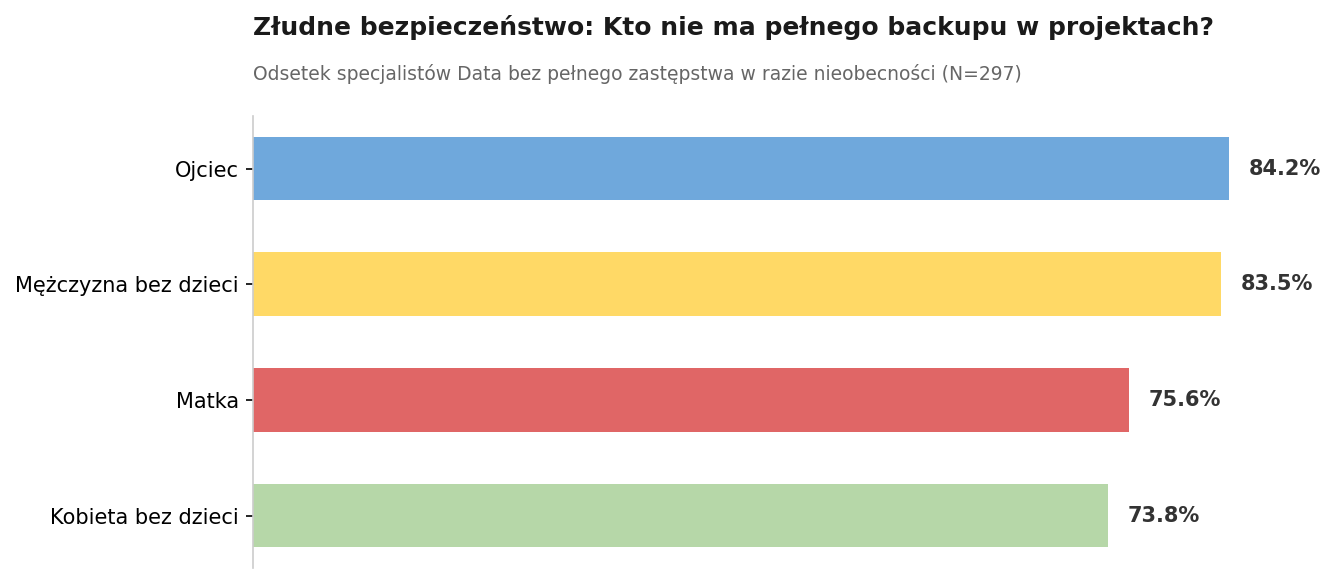

In [ ]:
# Kto NIE MA pełnego, bezproblemowego backupu (czyli wszystko poza 'tak')
brak_pelnego_backupu = (100 - tabela_backup['tak – jedna lub więcej osób zna szczegóły moich projektów i może mnie zastąpić']).round(1)

rysuj_wykres_filaru(
    brak_pelnego_backupu,
    tytul="Złudne bezpieczeństwo: Kto nie ma pełnego backupu w projektach?",
    podtytul="Odsetek specjalistów Data bez pełnego zastępstwa w razie nieobecności (N=297)"
)

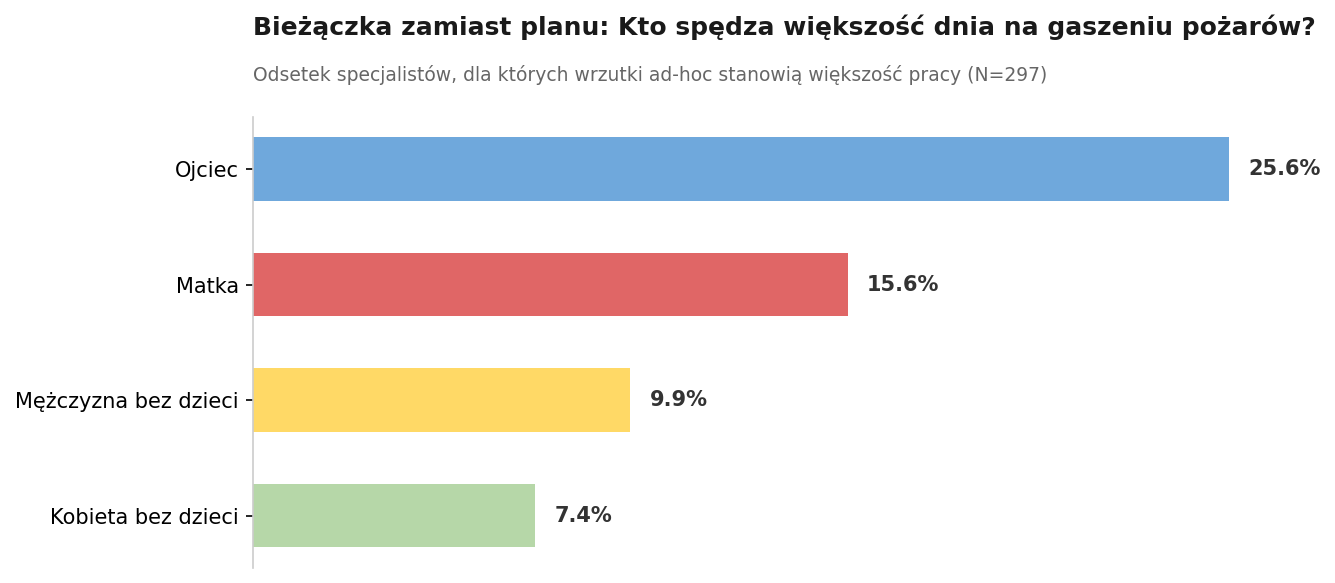

In [ ]:
# Filar 3: Zadania ad-hoc jako dominujący tryb pracy
adhoc_wiekszosc = tabela_adhoc['bardzo często, to większość mojej pracy']

rysuj_wykres_filaru(
    adhoc_wiekszosc,
    tytul="Bieżączka zamiast planu: Kto spędza większość dnia na gaszeniu pożarów?",
    podtytul="Odsetek specjalistów, dla których wrzutki ad-hoc stanowią większość pracy (N=297)"
)

**WNIOSKI (3 filar):**

Pożary ad-hoc uderzają w rodziców: Aż 25.6% ojców i 15.6% matek deklaruje, że nieplanowane zapytania i analizy „na wczoraj” stanowią większość ich pracy. Wśród specjalistów bez dzieci odsetek ten wynosi poniżej 10%. Rodzice stają się w zespołach Data domyślną „pierwszą linią frontu” dla biznesu.

W kwestii zastępstw (backupu) widać uderzającą różnicę.

Matki budują bufor bezpieczeństwa:
Zaledwie 11.1% matek nie posiada żadnego backupu w projektach (najniższy wynik w badaniu). Przewidując ryzyko nagłej nieobecności, kobiety-matki formalizują wiedzę i dbają o procedury zastępstw.

Prawie co trzeci ojciec (28.9%) deklaruje, że jest jedyną osobą znającą szczegóły swoich projektów, jednocześnie tonąc we wrzutkach ad-hoc.

Wniosek biznesowy: Brak formalnych procedur transferu wiedzy i chaotyczny przepływ zadań biznesowych tworzy potężne ryzyko operacyjne. Nagła nieobecność rodzica, który jest „samotną wyspą”, paraliżuje dostarczanie analiz ad-hoc dla interesariuszy.

### 2.4. Filar 4: Inwestycja w rozwój – weryfikacja mitu pasywnego rodzica

Odpowiedź na kluczowe pytanie o rozwój kompetencyjny: czy obciążenie domowe i zawodowe hamuje podnoszenie kwalifikacji w dynamicznie zmieniającej się branży?

In [ ]:
print("Warianty odpowiedzi - dokształcanie:")
print(df_rodzice['doksztalcanie'].value_counts(dropna=False))

print("\nWarianty odpowiedzi - rozwój w obecnej pracy:")
print(df_rodzice['rozwoj_w_pracy'].value_counts(dropna=False))

Warianty odpowiedzi - dokształcanie:
doksztalcanie
tak, regularnie                                             160
okazjonalnie                                                 96
nie, ale planuję w najbliższym czasie                        27
nie, na ten moment skupiam się na innych aspektach życia     12
NaN                                                           2
Name: count, dtype: int64

Warianty odpowiedzi - rozwój w obecnej pracy:
rozwoj_w_pracy
8.0     51
7.0     46
10.0    43
9.0     35
6.0     31
5.0     25
3.0     22
2.0     16
1.0     13
4.0     12
NaN      3
Name: count, dtype: int64


In [ ]:
# 1. Dokształcanie: Tabela rozkładu procentowego
tabela_doksztalcanie = (
    pd.crosstab(df_rodzice['profil_grupy'], df_rodzice['doksztalcanie'], normalize='index') * 100
).round(1)

print("DOKSZTAŁCANIE SIĘ (%)")
print(tabela_doksztalcanie)

DOKSZTAŁCANIE SIĘ (%)
doksztalcanie         nie, ale planuję w najbliższym czasie  \
profil_grupy                                                  
Kobieta bez dzieci                                     12.3   
Matka                                                   6.7   
Mężczyzna bez dzieci                                    8.9   
Ojciec                                                  2.6   

doksztalcanie         nie, na ten moment skupiam się na innych aspektach życia  \
profil_grupy                                                                     
Kobieta bez dzieci                                                  5.7          
Matka                                                               2.2          
Mężczyzna bez dzieci                                                3.3          
Ojciec                                                              2.6          

doksztalcanie         okazjonalnie  tak, regularnie  
profil_grupy                                        

In [ ]:
# 2. Poczucie rozwoju w pracy: Średnia ocena w skali 1-10
sredni_rozwoj = (
    df_rodzice.groupby('profil_grupy')['rozwoj_w_pracy']
    .agg(srednia_ocena='mean', mediana='median', liczba_odpowiedzi='count')
    .round(2)
)

print("POCZUCIE ROZWOJU NA STANOWISKU (Skala 1-10)")
print(sredni_rozwoj)

POCZUCIE ROZWOJU NA STANOWISKU (Skala 1-10)
                      srednia_ocena  mediana  liczba_odpowiedzi
profil_grupy                                                   
Kobieta bez dzieci             6.65      7.0                121
Matka                          6.67      7.0                 45
Mężczyzna bez dzieci           6.38      7.0                 90
Ojciec                         7.00      7.0                 38


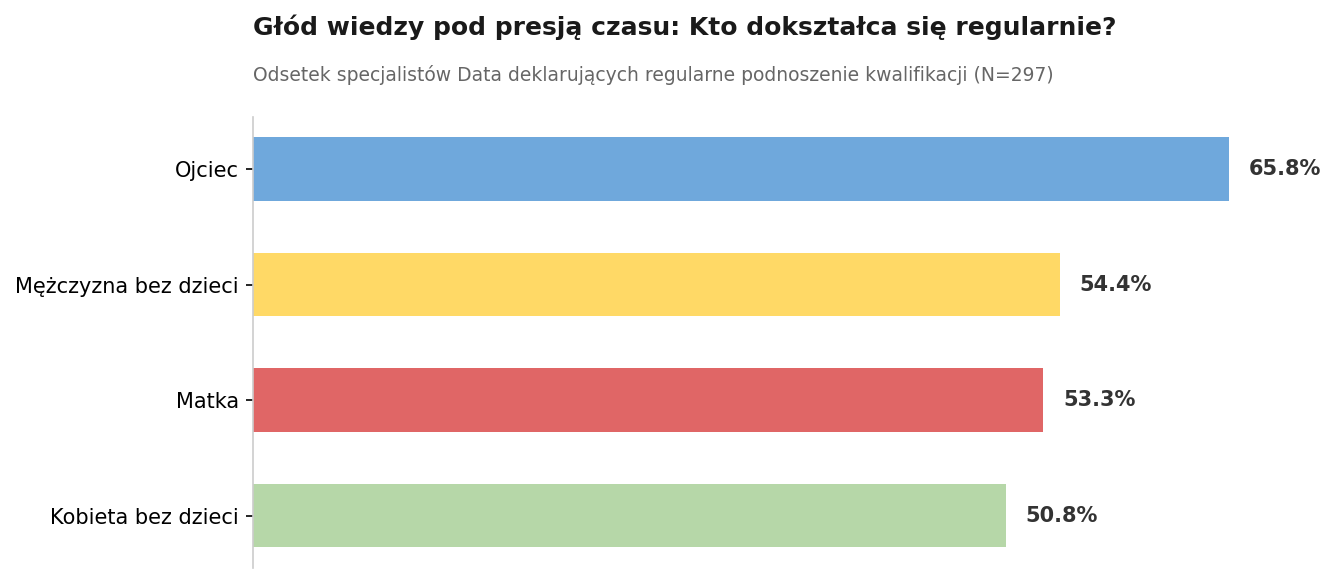

In [ ]:
# Filar 4: Regularne dokształcanie w podziale na profile
regularna_nauka = tabela_doksztalcanie['tak, regularnie']

rysuj_wykres_filaru(
    regularna_nauka,
    tytul="Głód wiedzy pod presją czasu: Kto dokształca się regularnie?",
    podtytul="Odsetek specjalistów Data deklarujących regularne podnoszenie kwalifikacji (N=297)"
)

**WNIOSKI (4 filar):**

Ojcowie liderami ciągłej edukacji: Aż 65.8% ojców dokształca się w sposób regularny - to najwyższy odsetek w całym badaniu (o ponad 11 p.p. wyższy niż u bezdzietnych mężczyzn: 54.4%).

Matki utrzymują wysokie tempo: 53.3% matek uczy się regularnie, przewyższając grupę kobiet bez dzieci (50.8%). Łącznie ponad 91% matek podnosi kwalifikacje stale lub okazjonalnie.

Rezygnację z nauki na rzecz innych sfer życia deklaruje zaledwie 2.2% matek i 2.6% ojców.

Zaangażowanie w naukę znajduje odzwierciedlenie w subiektywnej ocenie rozwoju na obecnym stanowisku (skala 1–10). Ojcowie notują najwyższą średnią w badaniu (7.00/10), a matki (6.67/10) wyprzedzają obie grupy bezdzietne (kobiety: 6.65, mężczyźni: 6.38).

## 3. Synteza wyników


Rodzicielstwo wymusza żelazną dyscyplinę. Blisko 70% rodziców (71.1% matek, 68.4% ojców) pracuje dokładnie 8 godzin dziennie, a odsetek pracujących powyżej 10h wynosi u nich równe 0.0%. Ciężar regularnych, cotygodniowych nadgodzin spoczywa głównie na osobach bezdzietnych (13.3% mężczyzn, 8.3% kobiet vs 2.2% matek).

Niedopasowanie obecnego modelu pracy do preferowanego dotyka częściej specjalistów bez dzieci (45.1% kobiet i 41.8% mężczyzn). U rodziców wskaźnik ten wynosi tylko 33.3%. Elastyczność i praca zdalna są dla nich twardym filtrem na etapie rekrutacji, a nie polem do kompromisów.

Rodzice stanowią pierwszą linię gaszenia pożarów biznesowych: wrzutki ad-hoc to większość pracy dla 25.6% ojców i 15.6% matek (wobec poniżej 10% u bezdzietnych). Jednocześnie 28.9% ojców nie ma żadnego backupu w projektach (Single Point of Failure), podczas gdy matki najsilniej w całej próbie dbają o formalne zastępstwa (tylko 11.1% bez backupu).

Dane obalają przekonanie, że rodzice odpuszczają rozwój merytoryczny. To ojcowie (65.8%) i matki (53.3%) najczęściej uczą się regularnie i najwyżej oceniają dynamikę swojego rozwoju na stanowisku, utrzymując przewagę nad grupami bezdzietnymi mimo znacznie większego deficytu wolnego czasu.